In [ ]:
%reset

import qutip as qt
from qutip.qip.operations import hadamard_transform

import numpy as np
import matplotlib.pyplot as plt

# basis and operators
zero = qt.basis(2, 0)
one = qt.basis(2, 1)
I = qt.qeye(2)
X = qt.sigmax()
Z = qt.sigmaz()
H = hadamard_transform()

# projectors computational basis
proj0 = zero * zero.dag()
proj1 = one * one.dag()

#print("teleporting:\n", psi_in)

# shared Bell pair between alice (qubit 1) and bob (qubit 2): (|00> + |11>) / sqrt(2)
bell = (qt.tensor(zero, zero) + qt.tensor(one, one)).unit()

# define gates
# qubit 0: Alice's input
# qubit 1: Alice's half of Bell pair
# qubit 2: Bob's half of Bell pair
# cnot with control on Q0 and target on Q1
cnot_01 = qt.tensor(proj0, I, I) + qt.tensor(proj1, X, I)
# hadamard on Q0
h_0 = qt.tensor(H, I, I)

# measurements and corresponding corrections on bob's qubit
outcomes = [
    (qt.tensor(proj0, proj0, I), qt.tensor(I, I, I)),           # outcome 00 -> no correction
    (qt.tensor(proj0, proj1, I), qt.tensor(I, I, X)),           # outcome 01 -> apply X
    (qt.tensor(proj1, proj0, I), qt.tensor(I, I, Z)),           # outcome 10 -> apply Z
    (qt.tensor(proj1, proj1, I), qt.tensor(I, I, Z * X))        # outcome 11 -> apply ZX
]





In [37]:


# noisy simulation
def noisy_simulation(noise_levels, noise_model,  rho_in_dm):
    def with_noise(p, noise_model):
        # add phase noise on the shared bell pair density matrix
        rho_bell = bell * bell.dag()
        rho_bell_noisy = noise_model(p, rho_bell)
        # total initial density matrix: rho_in ⊗ rho_bell_noisy
        rho_total = qt.tensor(rho_in_dm, rho_bell_noisy)
        
        # apply alice's operations: cnot  then hadamard
        rho_step1 = cnot_01 * rho_total * cnot_01.dag()
        rho_step2 = h_0 * rho_step1 * h_0.dag()
        
        # process measurement outcomes and bob's conditional corrections
        rho_bob_total = 0 *  qt.qeye(2) # qt.tensor(I, I)
        for projector, correction in outcomes:
            p_val = qt.expect(projector, rho_step2)
            if p_val > 1e-10:
                # post-measurement collapsed state
                collapsed = projector * rho_step2 * projector.dag() / p_val
                # bob's correction
                corrected = correction * collapsed * correction.dag()
                # partial trace over Alice's qubits to get bob's qubit
                rho_bob_i = corrected.ptrace(2)
                rho_bob_total += p_val * rho_bob_i
                
        # fidelity between input state and Bob's recovered state
        return qt.fidelity(rho_in_dm, rho_bob_total)**2
    
    fidelities = [with_noise(p, noise_model) for p in noise_levels]
    return fidelities


noise_levels = np.linspace(0.0, 0.5, 25)

I = qt.qeye(2)
X_bob = qt.tensor(I, qt.sigmax())
Y_bob = qt.tensor(I, qt.sigmay())
Z_bob = qt.tensor(I, qt.sigmaz())


def dephasing_noise(p, rho_bell):
    """Apply a phase flip to Bob's qubit with probability p."""
    return (1 - p) * rho_bell + p * (Z_bob * rho_bell * Z_bob.dag())


def depolarizing_noise(p, rho_bell):
    """Replace Bob's qubit with the maximally mixed state with probability p."""
    pauli_sum = (
        X_bob * rho_bell * X_bob.dag()
        + Y_bob * rho_bell * Y_bob.dag()
        + Z_bob * rho_bell * Z_bob.dag()
    )
    return (1 - 3 * p / 4) * rho_bell + (p / 4) * pauli_sum






teleporting Quantum object: dims=[[2], [2]], shape=(2, 2), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0.5 0.5]
 [0.5 0.5]]


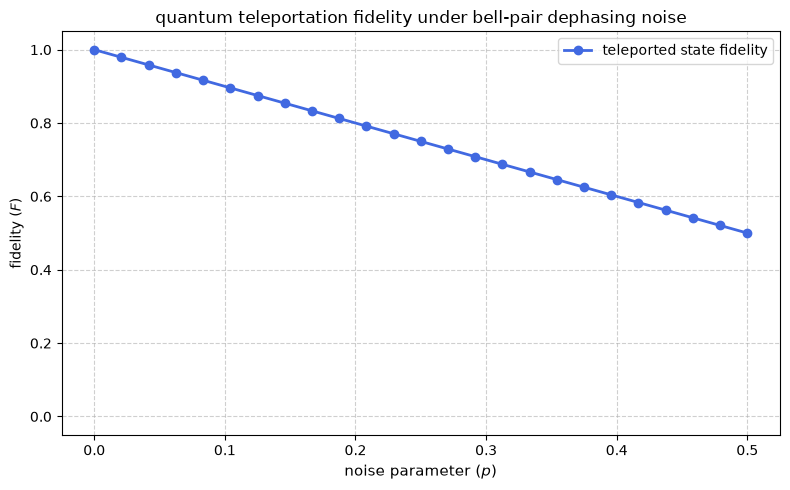

In [38]:
# define input the shared bell pair
# alice's random input state to teleport: |psi_in> = alpha|0> + beta|1>
alpha, beta = np.cos(np.pi / 6), np.sin(np.pi / 6) * 1j

psi_in = (alpha * zero + beta * one).unit()
psi_in = (zero + one).unit()

rho_in_dm = psi_in * psi_in.dag()
print("teleporting", rho_in_dm)


noise_type = "dephasing"
fidelities_dephasing = noisy_simulation(noise_levels, dephasing_noise,  rho_in_dm)

plt.figure(figsize=(8, 5))
plt.plot(noise_levels, fidelities_dephasing, marker='o', color='royalblue', lw=2, label='teleported state fidelity')
plt.title(f"quantum teleportation fidelity under bell-pair {noise_type} noise", fontsize=12)
plt.xlabel("noise parameter ($p$)", fontsize=11)
plt.ylabel("fidelity ($F$)")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

ok


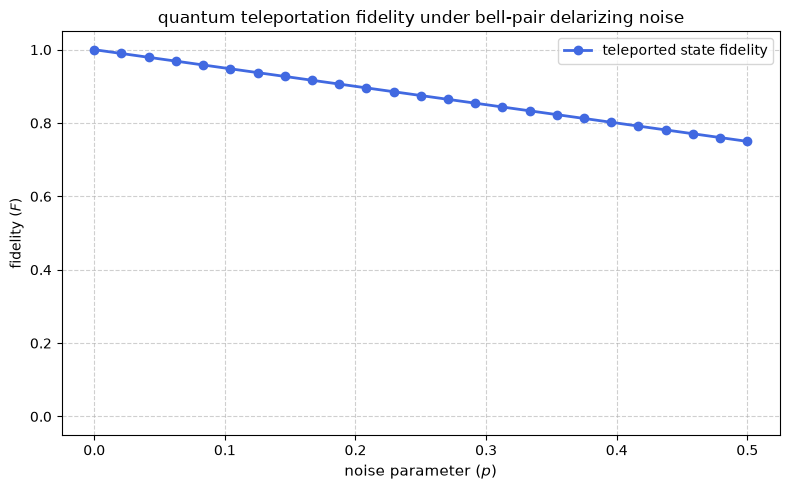

In [39]:
noise_type = "delarizing"
fidelities_depolarizing = noisy_simulation(noise_levels, depolarizing_noise, rho_in_dm)

print("ok")


plt.figure(figsize=(8, 5))
plt.plot(noise_levels, fidelities_depolarizing, marker='o', color='royalblue', lw=2, label='teleported state fidelity')
plt.title(f"quantum teleportation fidelity under bell-pair {noise_type} noise", fontsize=12)
plt.xlabel("noise parameter ($p$)", fontsize=11)
plt.ylabel("fidelity ($F$)")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()